# Predicting Song Popularity on Spotify Using Audio Features

**Predictive Analytics — Course Project**

This notebook reproduces the full analysis end to end:

1. Setup and data acquisition
2. Exploratory data analysis — the three structural findings
3. Preprocessing, deduplication and splitting
4. Hyperparameter tuning and regression models (RQ1, RQ3)
5. Classification comparison (RQ4)
6. Interpretation (RQ2)
7. Final held-out test evaluation, confusion matrices and verification
8. External validation and the era confound
9. Conclusion

**Research questions**

- **RQ1** How much variance in popularity is explained by audio features alone?
- **RQ2** Which audio features carry that signal, and in which direction?
- **RQ3** Does genre context materially improve on audio features alone?
- **RQ4** Is popularity easier to predict as a binary outcome than as a continuous score?

> **On data provenance.** Spotify deprecated the `audio_features` and `audio_analysis`
> endpoints on 27 November 2024, so this data cannot be collected first-hand. The analysis
> uses an archived pre-deprecation snapshot; see the report's Limitations section.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.width", 200)

RANDOM_STATE = 42

## 1. Data acquisition

Downloaded once from the HuggingFace mirror (BSD licence), pinned to the revision the study
used and checked against its SHA-256 (`data_prep.download_raw`).

In [2]:
from data_prep import download_raw, load_raw

download_raw()
raw = load_raw()
print(f"shape: {raw.shape}")
raw.head(3)

already present: C:\Users\ujjwa\OneDrive\Documents\Projects\Predictive\data\raw\dataset.csv


shape: (114000, 20)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.461,1,-6.746,0,0.1430,0.0322,0.000001,0.358,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.166,1,-17.235,1,0.0763,0.9240,0.000006,0.101,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.359,0,-9.734,1,0.0557,0.2100,0.000000,0.117,0.120,76.332,4,acoustic


In [3]:
raw.info()
print("\nNulls:")
print(raw.isna().sum()[raw.isna().sum() > 0])

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  str    
 1   artists           113999 non-null  str    
 2   album_name        113999 non-null  str    
 3   track_name        113999 non-null  str    
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           114000 non-nu

## 2. Exploratory data analysis

### 2.1 The file is not 114,000 independent observations

The dataset is built as 114 genres x 1,000 tracks. Because a track can belong to several
genres, the same `track_id` recurs across rows. Splitting without deduplicating puts the
**same song in train and test**, inflating every score. This is the single most consequential
issue in the dataset.

In [4]:
print(f"rows                : {len(raw):,}")
print(f"unique track_id     : {raw.track_id.nunique():,}")
dupes = len(raw) - raw.track_id.nunique()
print(f"duplicate rows      : {dupes:,}  ({100*dupes/len(raw):.1f}%)")

vc = raw.track_id.value_counts()
print(f"tracks in 2+ genres : {(vc > 1).sum():,}")
print(f"max genres per track: {vc.max()}")
print(f"genres              : {raw.track_genre.nunique()}")
print(f"rows per genre      : {raw.groupby('track_genre').size().unique()}")

rows                : 114,000
unique track_id     : 89,741
duplicate rows      : 24,259  (21.3%)


tracks in 2+ genres : 16,641
max genres per track: 9
genres              : 114
rows per genre      : [1000]


### 2.2 The target is zero-inflated, and the zeros are genre-clustered

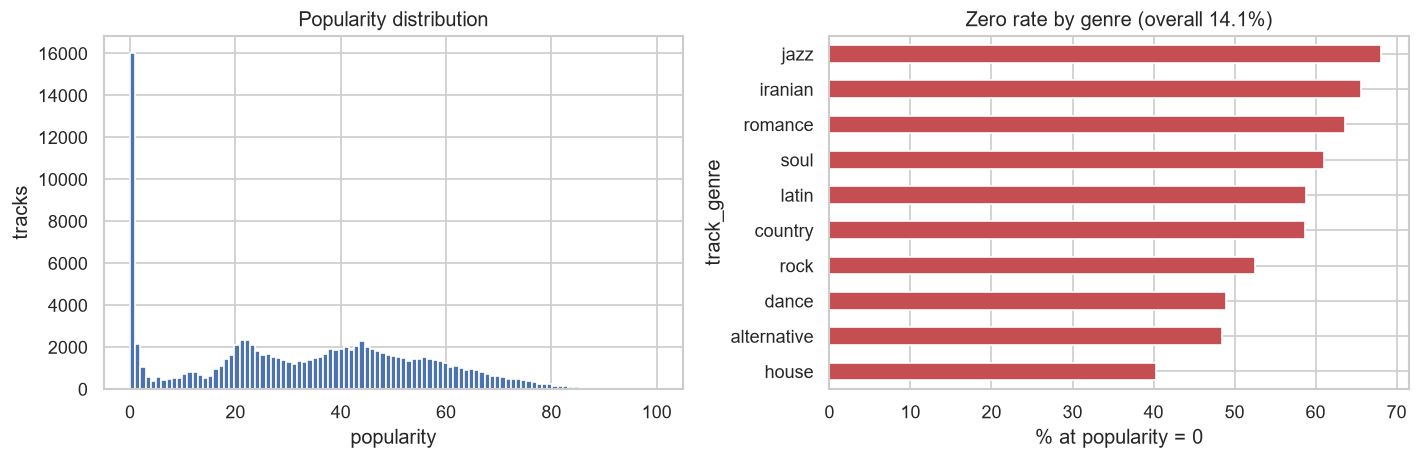

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(raw.popularity, bins=101, color="#4C72B0")
ax[0].set(title="Popularity distribution", xlabel="popularity", ylabel="tracks")

z = (raw.popularity == 0).mean()
zg = raw.assign(z=raw.popularity == 0).groupby("track_genre").z.mean() * 100
zg.sort_values(ascending=False).head(10).plot.barh(ax=ax[1], color="#C44E52")
ax[1].set(title=f"Zero rate by genre (overall {100*z:.1f}%)", xlabel="% at popularity = 0")
ax[1].invert_yaxis()
plt.tight_layout()
plt.show()

Jazz at 68% zero is not a musical fact. The clustering points to **regional licensing or
availability gaps at scrape time** — a different data-generating process from the popularity
score itself. This motivates the two-stage hurdle model later.

### 2.3 Linear associations with the target are negligible

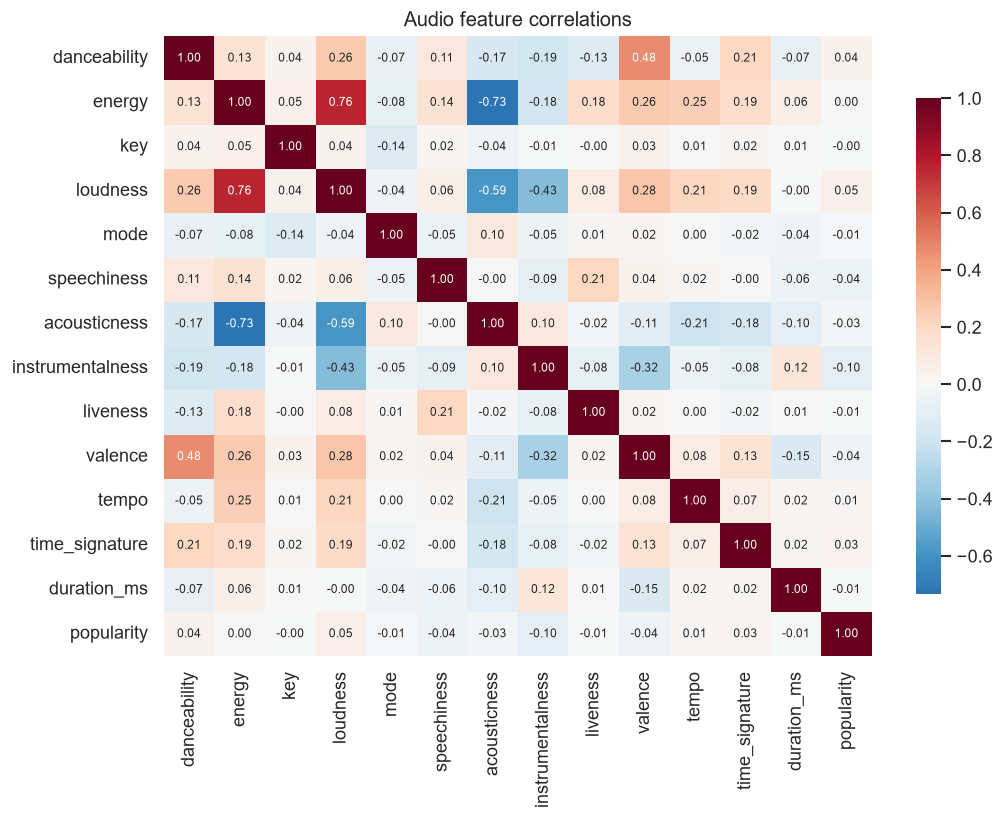

Correlation with popularity, strongest first:
instrumentalness   -0.0951
loudness            0.0504
speechiness        -0.0449
valence            -0.0405
danceability        0.0354
time_signature      0.0311
acousticness       -0.0255
mode               -0.0139
tempo               0.0132
duration_ms        -0.0071
liveness           -0.0054
key                -0.0039
energy              0.0011
Name: popularity, dtype: float64


In [6]:
from data_prep import AUDIO_FEATURES

corr = raw[AUDIO_FEATURES + ["popularity"]].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            annot_kws={"size": 7}, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Audio feature correlations")
plt.tight_layout()
plt.show()

print("Correlation with popularity, strongest first:")
print(corr["popularity"].drop("popularity").sort_values(key=abs, ascending=False).round(4))

No feature exceeds |r| = 0.10. The heatmap also shows the expected internal structure:
`energy` and `loudness` move together and both oppose `acousticness`. Formal VIF testing below.

In [7]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_cols = ["danceability", "energy", "loudness", "speechiness", "acousticness",
            "instrumentalness", "liveness", "valence", "tempo"]
X = raw[vif_cols].dropna()
vif = pd.DataFrame({
    "feature": vif_cols,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(len(vif_cols))],
}).sort_values("VIF", ascending=False)

print(vif.round(2).to_string(index=False))
print("\nVIF > 10 indicates problematic multicollinearity.")

         feature   VIF
           tempo 15.22
          energy 15.02
    danceability 12.32
        loudness  7.02
         valence  6.52
    acousticness  3.60
        liveness  2.57
     speechiness  1.80
instrumentalness  1.78

VIF > 10 indicates problematic multicollinearity.


## 3. Preprocessing and splitting

Implemented in `src/data_prep.py`:

- **Deduplicate** on `track_id`, keeping the first genre and recording `n_genres`
- **Clean** 163 impossible records (`tempo = 0`, `time_signature = 0`, zero duration)
- **Engineer**: `log1p` for four skewed features; duration in minutes, logged; `key`
  projected onto the unit circle via `sin`/`cos` — key 11 is adjacent to key 0, so an ordinal
  encoding would assert a distance that does not exist
- **Split** 70/15/15 stratified on binned popularity, with assertions that no `track_id`
  crosses partitions

In [8]:
from data_prep import build, split, feature_columns

df = build()
train, val, test = split(df)

print(f"analysis set : {len(df):,} unique tracks")
print(f"split        : {len(train):,} train / {len(val):,} val / {len(test):,} test")
print(f"zero-pop     : {100*df.is_zero_pop.mean():.1f}%")
print("\nLeakage assertions passed (see data_prep.split).")

analysis set : 89,578 unique tracks
split        : 62,704 train / 13,437 val / 13,437 test
zero-pop     : 10.5%

Leakage assertions passed (see data_prep.split).


## 4. Regression models (RQ1, RQ3)

Each model is fitted on two feature sets — **audio only** and **audio + genre** — so the
contribution of genre context is directly measurable. All preprocessing sits inside a
`Pipeline`, so scalers and encoders never see held-out data.

### 4.1 Hyperparameter tuning

Settings were chosen by cross-validated search **inside `train.csv` only** (`src/tuning.py`:
grid search for the regularisation strengths, randomised search for the tree ensembles, 3-fold
CV). Validation and test data were never loaded during the search. It takes about 20 minutes, so
it is not re-run here; its output is loaded below and every model in this notebook uses it.

In [9]:
import json
from models import load_best_params

tuning = pd.read_csv("../data/processed/results_tuning.csv")
display(tuning[["task", "features", "model", "scoring", "best_cv", "worst_cv", "candidates"]])
print(json.dumps(json.load(open("../data/processed/best_params.json")), indent=1)[:1500], "...")

,task,features,model,scoring,best_cv,worst_cv,candidates
0,regression,audio only,Ridge,r2,0.0339,0.0339,11
1,regression,audio only,Lasso,r2,0.0340,0.0155,7
2,regression,audio only,Random Forest,r2,0.2120,0.1693,8
3,regression,audio only,Gradient Boosting,r2,0.1763,0.1280,12
4,regression,audio+genre,Ridge,r2,0.3307,0.1749,11
5,regression,audio+genre,Lasso,r2,0.3307,0.0155,7
6,regression,audio+genre,Random Forest,r2,0.4568,0.2495,8
7,regression,audio+genre,Gradient Boosting,r2,0.4431,0.3763,12
8,classification,audio only,Logistic Regression,average_precision,0.3277,0.3273,6
9,classification,audio only,Random Forest,average_precision,0.4163,0.4052,8


{
 "regression": {
  "audio only": {
   "Ridge": {
    "alpha": 316.22776601683796
   },
   "Lasso": {
    "alpha": 0.03162277660168379
   },
   "Random Forest": {
    "min_samples_leaf": 1,
    "max_features": 0.5,
    "max_depth": null
   },
   "Gradient Boosting": {
    "min_samples_leaf": 10,
    "max_leaf_nodes": 127,
    "max_iter": 300,
    "learning_rate": 0.03,
    "l2_regularization": 1.0
   }
  },
  "audio+genre": {
   "Ridge": {
    "alpha": 3.1622776601683795
   },
   "Lasso": {
    "alpha": 0.001
   },
   "Random Forest": {
    "min_samples_leaf": 1,
    "max_features": 0.33,
    "max_depth": null
   },
   "Gradient Boosting": {
    "min_samples_leaf": 10,
    "max_leaf_nodes": 127,
    "max_iter": 300,
    "learning_rate": 0.08,
    "l2_regularization": 1.0
   }
  }
 },
 "classification": {
  "audio only": {
   "Logistic Regression": {
    "C": 0.001
   },
   "Random Forest": {
    "min_samples_leaf": 10,
    "max_features": 0.5,
    "max_depth": 30
   },
   "Gradient Bo

The gap between `best_cv` and `worst_cv` shows how much the settings matter. For the tree
ensembles they matter only modestly, which is the point of this step: the conclusions below do
not depend on lucky hyperparameters.

### 4.2 Validation comparison

In [10]:
from models import regression_models, HurdleRegressor, evaluate

# Only the best model so far per feature set is kept in memory: a tuned full-depth
# forest is about 2 GB, and section 6 needs just the validation winner.
rows, best = [], {}

def record(label, name, model, Xva, yva):
    m = evaluate(yva, model.predict(Xva))
    rows.append({"features": label, "model": name, **m})
    if name != "Mean baseline" and m["R2"] > best.get(label, (None, None, -1))[2]:
        best[label] = (name, model, m["R2"])

for label, inc in [("audio only", False), ("audio+genre", True)]:
    cols = feature_columns(include_genre=inc)
    params = load_best_params("regression", label)
    Xtr, ytr = train[cols], train.popularity
    Xva, yva = val[cols], val.popularity

    models = regression_models(cols, params)
    for name in list(models):
        record(label, name, models.pop(name).fit(Xtr, ytr), Xva, yva)

    h = HurdleRegressor(cols, gb_params=params.get("Gradient Boosting")).fit(Xtr, ytr)
    record(label, "Hurdle (2-stage)", h, Xva, yva)

val_results = pd.DataFrame(rows).round(4)
val_results

,features,model,R2,RMSE,MAE
0,audio only,Mean baseline,-0.0000,20.5793,17.2376
1,audio only,Linear Regression,0.0366,20.1994,16.6422
2,audio only,Ridge,0.0365,20.1998,16.6454
3,audio only,Lasso,0.0365,20.2005,16.6530
4,audio only,Random Forest,0.2546,17.7677,13.6425
5,audio only,Gradient Boosting,0.1877,18.5473,14.8049
6,audio only,Hurdle (2-stage),0.2001,18.4055,14.6223
7,audio+genre,Mean baseline,-0.0000,20.5793,17.2376
8,audio+genre,Linear Regression,0.3367,16.7602,12.0124
9,audio+genre,Ridge,0.3367,16.7602,12.0232


**RQ1.** Audio features alone reach validation R2 = 0.255
(Random Forest), and only 0.037 linearly. The relationship
is real but weak and thoroughly non-linear.

**RQ3.** Adding genre raises this to R2 = 0.499
(Random Forest).

> The **hurdle model** is defined only where a zero mass exists. In the zero-excluded
> sensitivity analysis below it is skipped: the stage-1 classifier would train on a single
> class and emit degenerate probabilities.

### 4.3 Sensitivity check — excluding zero-popularity tracks

In [11]:
df_nz = build(exclude_zeros=True)
tr_nz, va_nz, te_nz = split(df_nz)

rows = []
for label, inc in [("audio only", False), ("audio+genre", True)]:
    cols = feature_columns(include_genre=inc)
    for name in ["Random Forest", "Gradient Boosting"]:
        m = regression_models(cols, load_best_params("regression", label))[name]
        m.fit(tr_nz[cols], tr_nz.popularity)
        rows.append({"features": label, "model": f"{name} (zeros excluded)",
                     **evaluate(va_nz.popularity, m.predict(va_nz[cols]))})

pd.DataFrame(rows).round(4)

,features,model,R2,RMSE,MAE
0,audio only,Random Forest (zeros excluded),0.2092,16.1361,12.7264
1,audio only,Gradient Boosting (zeros excluded),0.2016,16.2130,12.9352
2,audio+genre,Random Forest (zeros excluded),0.5204,12.5661,8.8731
3,audio+genre,Gradient Boosting (zeros excluded),0.5216,12.5500,8.7511


With the zero mass removed, the best audio-only R2 is 0.209 (versus
0.255 with zeros) and the best audio+genre R2 is
0.522 (versus 0.499). Genre context gains and
audio-only loses: the zeros were partly predictable from audio characteristics, consistent with
them marking a distinct availability process.

## 5. Classification comparison (RQ4)

The threshold is a **modelling choice, not a property of the data**. The primary cut is the
75th percentile of non-zero popularity; `src/run_classification.py` repeats everything at the
90th percentile as a sensitivity check.

Metrics are ROC-AUC and PR-AUC rather than accuracy, which is misleading under imbalance.

In [12]:
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, confusion_matrix)
from models import classification_models

nz = train.loc[train.popularity > 0, "popularity"]
thr = nz.quantile(0.75)
ytr = (train.popularity >= thr).astype(int)
yva = (val.popularity >= thr).astype(int)
print(f"threshold: popularity >= {thr:.0f}   positive rate = {ytr.mean():.1%}")

rows = []
for label, inc in [("audio only", False), ("audio+genre", True)]:
    cols = feature_columns(include_genre=inc)
    models = classification_models(cols, load_best_params("classification", label))
    for name in list(models):
        clf = models.pop(name).fit(train[cols], ytr)
        p = clf.predict_proba(val[cols])[:, 1]
        rows.append({"features": label, "model": name,
                     "ROC_AUC": roc_auc_score(yva, p),
                     "PR_AUC": average_precision_score(yva, p),
                     "F1": f1_score(yva, (p >= 0.5).astype(int)),
                     "PR_baseline": yva.mean()})

val_clf = pd.DataFrame(rows).round(4)
val_clf

threshold: popularity >= 50   positive rate = 23.7%


,features,model,ROC_AUC,PR_AUC,F1,PR_baseline
0,audio only,Logistic Regression,0.6281,0.3359,0.4077,0.2365
1,audio only,Random Forest,0.7186,0.4351,0.4231,0.2365
2,audio only,Gradient Boosting,0.7127,0.4322,0.1331,0.2365
3,audio+genre,Logistic Regression,0.8345,0.5989,0.5834,0.2365
4,audio+genre,Random Forest,0.8713,0.6806,0.5557,0.2365
5,audio+genre,Gradient Boosting,0.8753,0.6956,0.5579,0.2365


**RQ4.** The binary framing looks stronger (test ROC-AUC
0.87 with genre), but this is partly presentational:
ROC-AUC 0.72 from audio alone reflects the same weak
underlying signal as R2 0.27. Discretising the target discards
information and makes a modest relationship look more decisive than it is.

## 6. Interpretation (RQ2)

Permutation importance is preferred over impurity-based importance here, because the
collinearity documented in section 2.3 inflates impurity importances for correlated features.
It is computed for the validation-selected regressor of each feature set.

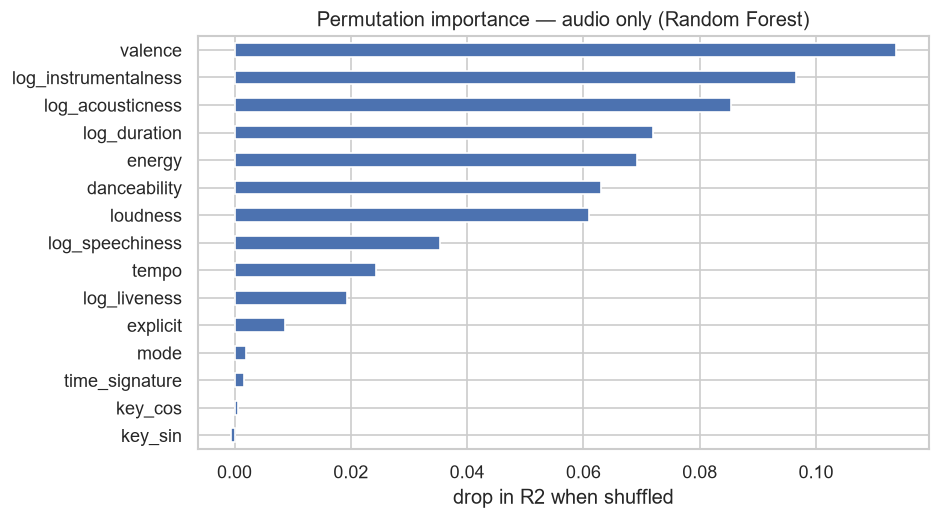

audio only: top 5
valence                 0.1137
log_instrumentalness    0.0966
log_acousticness        0.0854
log_duration            0.0719
energy                  0.0692
dtype: float64


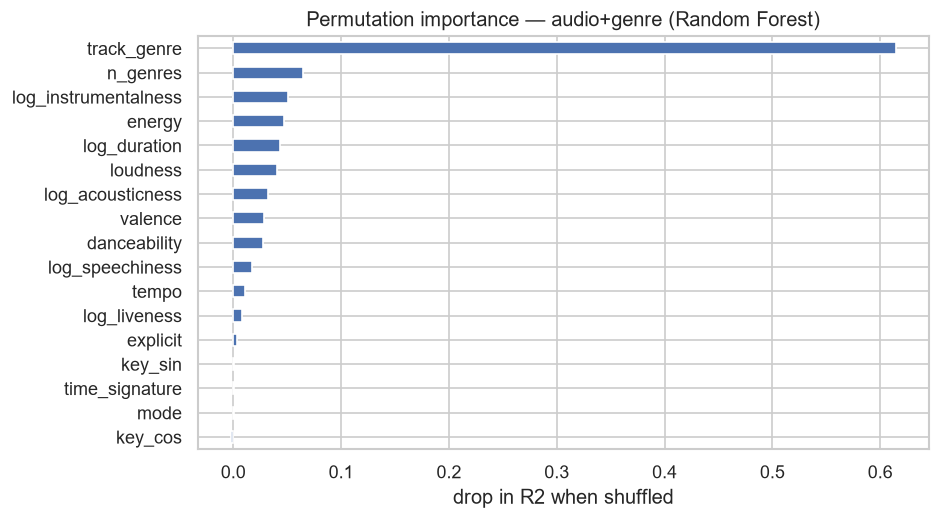

audio+genre: top 5
track_genre             0.6142
n_genres                0.0649
log_instrumentalness    0.0504
energy                  0.0467
log_duration            0.0432
dtype: float64


In [13]:
from sklearn.inspection import permutation_importance

winners = {label: name for label, (name, _, _) in best.items()}

sub = val.sample(3000, random_state=RANDOM_STATE)
for label, inc in [("audio only", False), ("audio+genre", True)]:
    cols = feature_columns(include_genre=inc)
    mdl = best[label][1]
    pi = permutation_importance(mdl, sub[cols], sub.popularity, n_repeats=3, scoring="r2",
                                random_state=RANDOM_STATE, n_jobs=1)
    imp = pd.Series(pi.importances_mean, index=cols).sort_values()

    fig, ax = plt.subplots(figsize=(8, 4.5))
    imp.plot.barh(ax=ax, color="#4C72B0")
    ax.set(title=f"Permutation importance — {label} ({winners[label]})",
           xlabel="drop in R2 when shuffled")
    plt.tight_layout()
    plt.show()
    print(f"{label}: top 5")
    print(imp.sort_values(ascending=False).head(5).round(4))

**Genre outweighs the strongest audio feature (`log_duration`) by roughly 13 times**
on the held-out test set (permutation importance 0.594 versus 0.046;
`data/processed/perm_importance_genre.csv`). This is the central empirical finding.

Within audio features, SHAP confirms the permutation ranking.

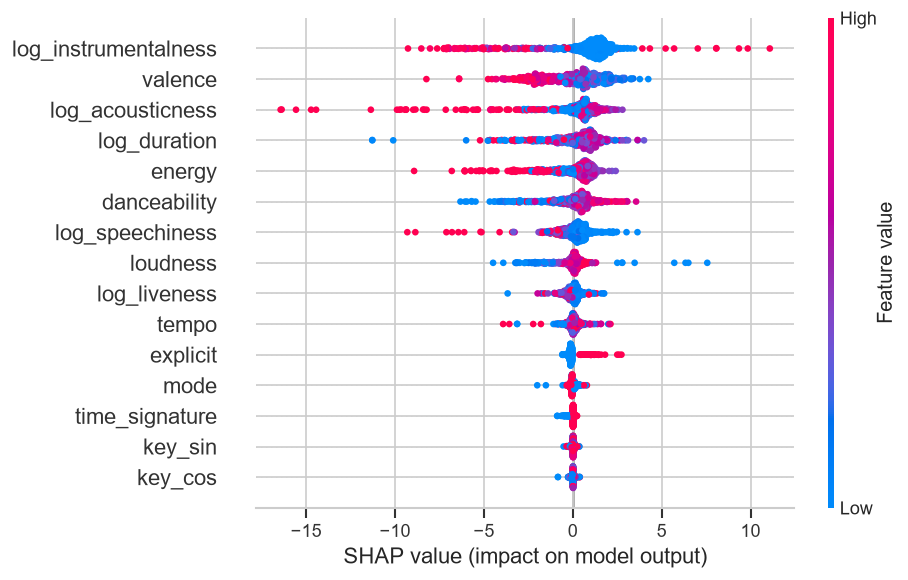

In [14]:
import shap
from sklearn.ensemble import RandomForestRegressor

cols = feature_columns(include_genre=False)
# Shallower forest keeps TreeExplainer tractable without changing the ranking.
rf = RandomForestRegressor(n_estimators=60, max_depth=12, min_samples_leaf=20,
                           n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(train[cols], train.popularity)

sample = val[cols].sample(600, random_state=RANDOM_STATE)
sv = shap.TreeExplainer(rf).shap_values(sample)
shap.summary_plot(sv, sample, plot_size=(8, 5))

**RQ2.** Instrumentalness and acousticness push predicted popularity **down** — vocal,
produced tracks score higher. Key and mode are effectively inert: **the musical key of a song
carries no information about its popularity.**

## 7. Final test evaluation and verification

The winner for each feature set is the validation-selected model from sections 4.2 and 5,
refitted on train + validation with its tuned settings. The mean baseline and linear regression
are reported alongside as reference points.

> **Disclosure.** The DA1 proposal reported preliminary test numbers from an untuned run. The
> test set was therefore scored once before this final run. No setting was chosen by looking at
> those numbers: tuning used only `train.csv`, and selection used only validation. This run is
> the frozen protocol that the proposal announced.

In [15]:
del best   # release the validation fits before refitting on train + validation
trval = pd.concat([train, val], ignore_index=True)

def regressor(name, cols, params):
    if name == "Hurdle (2-stage)":
        return HurdleRegressor(cols, gb_params=params.get("Gradient Boosting"))
    return regression_models(cols, params)[name]

rows = []
for label, inc in [("audio only", False), ("audio+genre", True)]:
    cols = feature_columns(include_genre=inc)
    params = load_best_params("regression", label)
    for name in dict.fromkeys(["Mean baseline", "Linear Regression", winners[label]]):
        est = regressor(name, cols, params).fit(trval[cols], trval.popularity)
        rows.append({"features": label, "model": name, "selected": name == winners[label],
                     **evaluate(test.popularity, est.predict(test[cols]),
                                n_features=len(cols))})
        del est

pd.DataFrame(rows).round(4)

,features,model,selected,R2,RMSE,MAE,Adj_R2
0,audio only,Mean baseline,False,-0.0000,20.6365,17.3086,-0.0011
1,audio only,Linear Regression,False,0.0344,20.2780,16.7207,0.0334
2,audio only,Random Forest,True,0.2662,17.6773,13.5729,0.2654
3,audio+genre,Mean baseline,False,-0.0000,20.6365,17.3086,-0.0013
4,audio+genre,Linear Regression,False,0.3235,16.9737,12.1605,0.3226
5,audio+genre,Random Forest,True,0.5009,14.5789,9.9151,0.5003


### 7.1 Classification on the test set, with confusion matrices

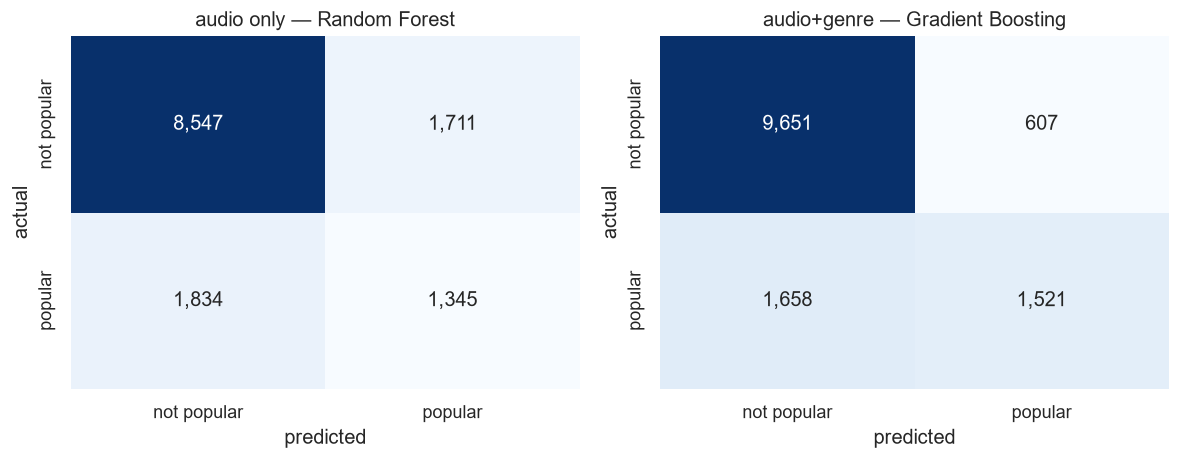

,features,model,ROC_AUC,PR_AUC,Precision,Recall,F1,PR_baseline
0,audio only,Random Forest,0.7244,0.4353,0.4401,0.4231,0.4314,0.2366
1,audio+genre,Gradient Boosting,0.8728,0.6869,0.7148,0.4785,0.5732,0.2366


In [16]:
thr = trval.loc[trval.popularity > 0, "popularity"].quantile(0.75)
ytrval = (trval.popularity >= thr).astype(int)
yte = (test.popularity >= thr).astype(int)

rows = []
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (label, inc) in zip(axes, [("audio only", False), ("audio+genre", True)]):
    cols = feature_columns(include_genre=inc)
    name = val_clf[val_clf.features == label].sort_values("PR_AUC").iloc[-1].model
    clf = classification_models(cols, load_best_params("classification", label))[name]
    clf.fit(trval[cols], ytrval)
    p = clf.predict_proba(test[cols])[:, 1]
    pred = (p >= 0.5).astype(int)
    rows.append({"features": label, "model": name,
                 "ROC_AUC": roc_auc_score(yte, p), "PR_AUC": average_precision_score(yte, p),
                 "Precision": precision_score(yte, pred), "Recall": recall_score(yte, pred),
                 "F1": f1_score(yte, pred), "PR_baseline": yte.mean()})
    sns.heatmap(confusion_matrix(yte, pred), annot=True, fmt=",d", cmap="Blues", cbar=False,
                ax=ax, xticklabels=["not popular", "popular"],
                yticklabels=["not popular", "popular"])
    ax.set(title=f"{label} — {name}", xlabel="predicted", ylabel="actual")
plt.tight_layout()
plt.show()

pd.DataFrame(rows).round(4)

### 7.2 Verification: shuffled-target check

Refitting on a permuted target must collapse R2 to approximately zero. Anything else indicates
leakage.

In [17]:
from models import shuffle_check

cols = feature_columns(include_genre=True)
gb = regression_models(cols, load_best_params("regression", "audio+genre"))["Gradient Boosting"]
r2s = shuffle_check(gb, train[cols], train.popularity, val[cols], val.popularity)
print(f"shuffled-target R2 = {r2s:.5f}  ->  "
      f"{'PASS' if abs(r2s) < 0.02 else 'FAIL - LEAKAGE'}")

shuffled-target R2 = -0.00088  ->  PASS


### 7.3 Verification: seed variance

`src/run_seed_variance.py` refits the tuned Random Forest on five train/validation partitions
(seeds 42, 1–4). Only the 85% pool shared by train and validation is re-partitioned; the test
set stays fixed and is not scored again. Refitting takes several minutes, so its output is
loaded here.

In [18]:
seeds = pd.read_csv("../data/processed/results_seed_variance.csv")
display(seeds)
seeds.groupby("features").R2.agg(["mean", "std"]).round(4)

,seed,features,model,n_train,n_val,R2,RMSE,MAE
0,42,audio only,Random Forest,62704,13437,0.2546,17.7677,13.6425
1,42,audio+genre,Random Forest,62704,13437,0.4989,14.5675,9.8758
2,1,audio only,Random Forest,62704,13437,0.2462,17.9051,13.7335
3,1,audio+genre,Random Forest,62704,13437,0.4943,14.6661,9.9784
4,2,audio only,Random Forest,62704,13437,0.2673,17.5995,13.5060
5,2,audio+genre,Random Forest,62704,13437,0.5131,14.3474,9.7739
6,3,audio only,Random Forest,62704,13437,0.2316,18.0234,13.7496
7,3,audio+genre,Random Forest,62704,13437,0.4906,14.6745,9.9130
8,4,audio only,Random Forest,62704,13437,0.2524,17.7921,13.5948
9,4,audio+genre,Random Forest,62704,13437,0.4931,14.6501,9.8562


,mean,std
features,,
audio only,0.2504,0.013
audio+genre,0.4980,0.009


Validation R2 is **0.250 ± 0.013**
audio only and **0.498 ± 0.009**
audio + genre (mean ± SD). The gain from genre, about
0.25, is far larger than the
seed-to-seed spread.

## 8. External validation and the era confound

The primary dataset has no release year, so one obvious confound could not be tested there:
recording loudness and production style have changed for decades, and Spotify popularity
favours recent releases, so audio features may partly stand in for **when** a song was made.

The **Spotify Audio Features Hit Predictor Dataset (1960–2019)** (Ansari, 4TU.ResearchData,
GPL-3.0) carries the same audio features, a decade for every track, and an independent
hit/flop label based on the Billboard Hot 100. `src/external_data.py` downloads it (MD5-checked)
and removes every song the primary dataset also holds, matched both by Spotify ID and by artist
and title. The second match matters: re-released songs get new IDs, and the songs it catches are
disproportionately hits.

### 8.1 Transfer: does the primary model generalise?

The audio-only classifier is trained on primary train + validation (the primary test set is not
used) and scored on every external track. The targets differ, so this tests whether the
*direction* of the audio signal carries over, not whether the scores match.

In [19]:
from data_prep import feature_columns

ext = pd.read_csv("../data/processed/external_clean.csv")
print(f"external tracks: {len(ext):,}   hit rate: {ext.target.mean():.1%}")

cols_x = feature_columns(include_genre=False, include_explicit=False)  # no `explicit` there
thr = trval.loc[trval.popularity > 0, "popularity"].quantile(0.75)
name = val_clf[val_clf.features == "audio only"].sort_values("PR_AUC").iloc[-1].model
clf = classification_models(cols_x, load_best_params("classification", "audio only"))[name]
clf.fit(trval[cols_x], (trval.popularity >= thr).astype(int))
ext["p_popular"] = clf.predict_proba(ext[cols_x])[:, 1]

rows = [{"decade": "all", "n": len(ext), "ROC_AUC": roc_auc_score(ext.target, ext.p_popular)}]
for d, part in ext.groupby("decade"):
    rows.append({"decade": d, "n": len(part),
                 "ROC_AUC": roc_auc_score(part.target, part.p_popular)})
pd.DataFrame(rows).round(4)

external tracks: 37,431   hit rate: 47.5%


,decade,n,ROC_AUC
0,all,37431,0.6906
1,1960,8301,0.5949
2,1970,7319,0.6413
3,1980,6324,0.6824
4,1990,4949,0.7418
5,2000,5215,0.7970
6,2010,5323,0.7940


Trained only on Spotify popularity, the audio model separates Billboard hits from non-hits
with ROC-AUC **0.69** (95% bootstrap CI 0.686–0.695).
The audio signal is real and transfers. But it is **not uniform across time**: AUC rises steadily
from **0.59** for 1960s tracks to **0.80** for the
2000s. The model has learned what *recent* popular music sounds like.

### 8.2 Measuring the era confound

`src/run_external.py` makes four measurements within the external dataset:

,test,variant,value
0,B1 drift 1960s->2010s (SD units),loudness,0.8045
1,B1 drift 1960s->2010s (SD units),energy,0.8833
2,B1 drift 1960s->2010s (SD units),acousticness,-1.1742
3,B1 drift 1960s->2010s (SD units),danceability,0.3978
4,B1 drift 1960s->2010s (SD units),valence,-0.4883
5,B1 drift 1960s->2010s (SD units),log_duration,0.7047
6,B2 decade from audio (5-fold CV R2),Gradient Boosting,0.5199
7,B3 hit AUC (5-fold CV),"Logistic Regression, audio",0.8011
8,B3 hit AUC (5-fold CV),"Logistic Regression, audio+decade",0.8083
9,B3 AUC gain from decade,Logistic Regression,0.0073


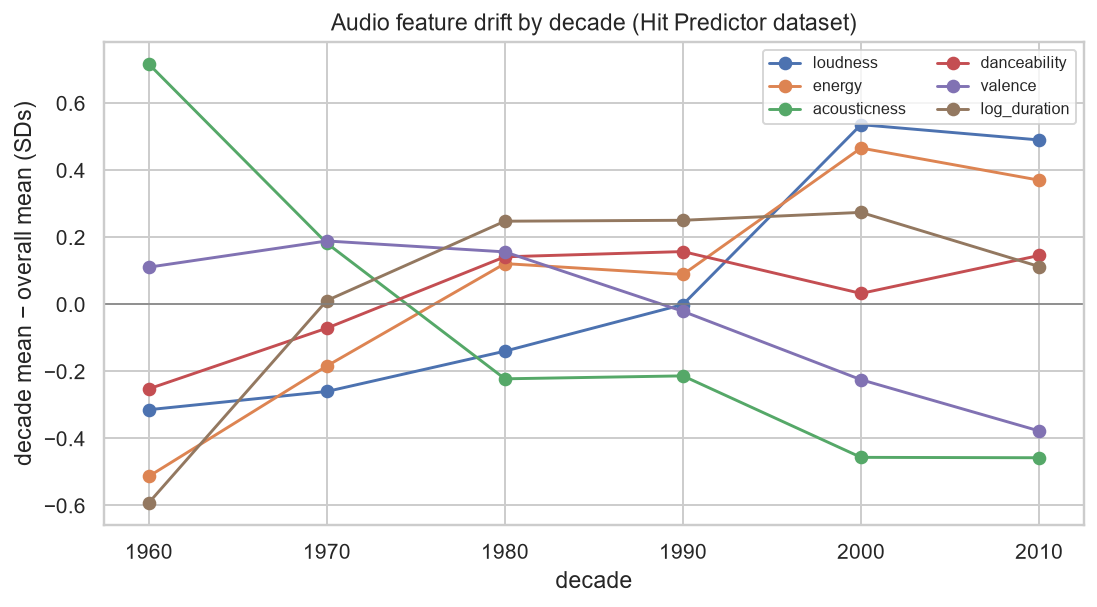

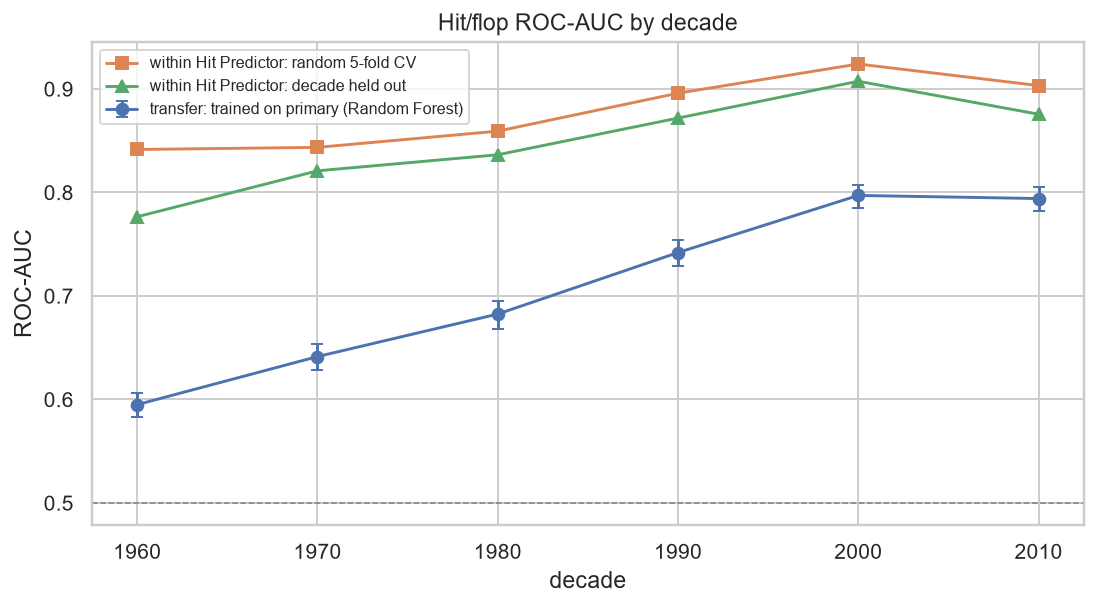

In [20]:
from IPython.display import Image, display

era = pd.read_csv("../data/processed/results_era.csv")
display(era)
display(Image("../figures/10_feature_drift_by_decade.png", width=720))
display(Image("../figures/11_transfer_auc_by_decade.png", width=720))

- **Drift.** Loudness and energy rise by roughly 0.8–1 standard deviation between the 1960s
  and the 2010s, while acousticness falls by more than one.
- **Audio predicts era.** From audio features alone, a track's decade is recovered with
  cross-validated R2 = **0.52**. Audio features
  are, to a substantial degree, a timestamp.
- **What makes a hit depends on era.** Giving the hit model the decade raises its ROC-AUC by
  **+0.024** (Gradient Boosting).
- **Unseen eras are harder.** When a decade is held out entirely, AUC falls by
  **0.030** on average, and by most for the 1960s.

**Conclusion on the confound.** Part of what the primary study calls the "audio signal" is an era
signal: modern-sounding tracks are popular partly because modern tracks are popular. The DA1
proposal could only acknowledge this. It is now measured, and it is large enough to matter for
how the audio-only result is read, though not large enough to erase it. The transfer AUC stays
above 0.5 in every decade.

> **Caveat.** Within the Hit Predictor data, audio alone separates hits from flops far more
> easily (AUC about 0.87) than anything in the primary study. Its flops were drawn from
> non-charting tracks, which skews them towards non-mainstream genres, so the hit/flop label
> partly encodes genre. The within-dataset numbers are therefore used only for *relative*
> comparisons (with versus without decade, random versus held-out decade), never as an absolute
> measure of predictability.

## 9. Conclusion

Audio features alone explain about **27% of the variance** in Spotify
popularity on the held-out test set (R2 = 0.266, tuned
Random Forest), and almost none of it linearly
(R2 = 0.034). Adding genre context nearly **doubles** explanatory power to
**50%**, and permutation testing shows genre outweighing the strongest
audio feature by about **13 times**.

Two further results qualify the audio-only figure:

1. **It generalises.** A model trained on Spotify popularity identifies Billboard hits in an
   independent dataset with ROC-AUC 0.69.
2. **It is partly an era effect.** That transfer works far better for recent decades
   (0.80) than for the 1960s (0.59), and audio
   features recover a track's decade with R2 = 0.52.

**How a song sounds constrains its popularity far less than what category it occupies, when it
was made, and how it is marketed.** Instrumental and acoustic recordings are systematically less
popular; vocal, produced, moderate-length tracks score higher; and the key a song is written in
carries no signal whatsoever.

All numbers in this section are read from `data/processed/` when the notebook is generated.